# Tree-Based Prediction of 5-Year Mortality in Stage III Colon Cancer

**Project:** Colorectal Cancer Survival Analysis (notebook 2)
**Author:** Preston Laney
**Methods:** Decision tree, random forest, gradient boosting (scikit-learn, XGBoost), Cox proportional hazards reference model

---

## Background and objective

Notebook 1 modeled overall survival in the NCCTG stage III colon cancer trial with Kaplan-Meier curves and Cox proportional hazards regression. Cox imposes two structural assumptions: each covariate acts log-linearly on the hazard, and covariates act independently unless an interaction term is specified. Tree-based models relax both. A single tree partitions the cohort with data-driven thresholds; gradient boosting fits an additive sequence of shallow trees and can represent arbitrary per-feature response shapes and, at depth 2 or more, interactions.

This notebook asks whether tree-based models improve on Cox for a concrete prognostic task:

> Using covariates available at surgery (age, sex, nodal burden, differentiation, depth of invasion, obstruction, perforation, adherence, surgery-to-registration interval) and the assigned adjuvant arm, predict which patients die within 5 years.

Models are compared on a held-out test set by discrimination (AUC with bootstrap confidence intervals), probability quality (log loss, Brier score), and calibration. Permutation importance and partial dependence are used to characterize what the best model learned and where it departs from the Cox fit.

---
## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, RocCurveDisplay
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibrationDisplay

from xgboost import XGBClassifier
from lifelines import CoxPHFitter

PROJECT_DIR = r"C:/Users/palla/OneDrive/Documents/Coding Projects/SEER"
DATA_PATH = os.path.join(PROJECT_DIR, "data", "colon_ncctg.csv")
ASSETS_DIR = os.path.join(PROJECT_DIR, "assets")
os.makedirs(ASSETS_DIR, exist_ok=True)

RANDOM_SEED = 42

# Fixed series palette, assigned in order
COLOR_BLUE = "#2a78d6"
COLOR_ORANGE = "#eb6834"
COLOR_AQUA = "#1baf7a"
COLOR_GRAY = "#9a9a94"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": COLOR_GRAY,
    "axes.grid": True,
    "grid.color": "#e6e6e2",
    "grid.linewidth": 0.6,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

import sklearn, xgboost, lifelines
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("lifelines", lifelines.__version__)

pandas 2.3.3
scikit-learn 1.8.0
xgboost 3.4.1
lifelines 0.30.3


---
## 2. Data

NCCTG colon cancer trial (Moertel et al., NEJM 1990): 929 patients with resected stage III colon cancer randomized to observation, levamisole, or levamisole plus 5-fluorouracil. The public file carries two rows per patient, one for the recurrence endpoint (`etype == 1`) and one for death (`etype == 2`), with identical baseline covariates on both. The rows are pivoted to one record per patient carrying both endpoints.

A local copy is cached in `data/` and downloaded once if absent.

In [2]:
if not os.path.exists(DATA_PATH):
    os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
    source_url = "https://vincentarelbundock.github.io/Rdatasets/csv/survival/colon.csv"
    pd.read_csv(source_url, index_col=0).to_csv(DATA_PATH, index=False)
    print("Downloaded and cached:", DATA_PATH)

raw_two_rows_per_patient = pd.read_csv(DATA_PATH)
print("Raw shape (two rows per patient):", raw_two_rows_per_patient.shape)
raw_two_rows_per_patient.head(4)

Raw shape (two rows per patient): (1858, 16)


,id,study,rx,sex,age,obstruct,perfor,adhere,nodes,status,differ,extent,surg,node4,time,etype
0,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,1521,2
1,1,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,968,1
2,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,2
3,2,1,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,1


In [3]:
death_rows = raw_two_rows_per_patient[raw_two_rows_per_patient["etype"] == 2].copy()
recurrence_rows = raw_two_rows_per_patient[raw_two_rows_per_patient["etype"] == 1].copy()

death_rows = death_rows.rename(columns={"status": "died", "time": "time_to_death_days", "rx": "treatment"})
death_rows["time_to_death_years"] = death_rows["time_to_death_days"] / 365.25

recurrence_endpoint = recurrence_rows[["id", "status", "time"]].rename(
    columns={"status": "recurred", "time": "time_to_recurrence_days"}
)
recurrence_endpoint["time_to_recurrence_years"] = recurrence_endpoint["time_to_recurrence_days"] / 365.25

# One record per patient with both endpoints; study is constant and etype is now redundant
patients = death_rows.merge(recurrence_endpoint, on="id", how="left").drop(columns=["study", "etype"])

print("Patients:", len(patients))
print("Deaths:", int(patients["died"].sum()), f"({patients['died'].mean():.1%})")
print("Recurrences:", int(patients["recurred"].sum()), f"({patients['recurred'].mean():.1%})")
print("Median follow-up (years):", round(patients["time_to_death_years"].median(), 2))
patients.head()

Patients: 929
Deaths: 452 (48.7%)
Recurrences: 468 (50.4%)
Median follow-up (years): 5.41


,id,treatment,sex,age,obstruct,perfor,adhere,nodes,died,differ,extent,surg,node4,time_to_death_days,time_to_death_years,recurred,time_to_recurrence_days,time_to_recurrence_years
0,1,Lev+5FU,1,43,0,0,0,5.0,1,2.0,3,0,1,1521,4.164271,1,968,2.650240
1,2,Lev+5FU,1,63,0,0,0,1.0,0,2.0,3,0,0,3087,8.451745,0,3087,8.451745
2,3,Obs,0,71,0,0,1,7.0,1,2.0,2,0,1,963,2.636550,1,542,1.483915
3,4,Lev+5FU,0,66,1,0,0,6.0,1,2.0,3,1,1,293,0.802190,1,245,0.670773
4,5,Obs,1,69,0,0,0,22.0,1,2.0,3,1,1,659,1.804244,1,523,1.431896


---
## 3. Outcome definition

The classifiers require a binary outcome. Vital status at last contact is not usable directly: a patient censored alive at 2 years has unknown 5-year status, and labeling them as a survivor would encode follow-up length as a prognostic signal.

The outcome is therefore defined by a 5-year landmark:

| Follow-up pattern | Label |
|---|---|
| Death before 5 years | 1 |
| Followed at least 5 years (alive or died later) | 0 |
| Censored alive before 5 years | excluded |

Follow-up in this trial is long enough that the exclusion is small. The Cox reference model is fit on the full time-to-event data and does not require the landmark; it retains the patients the classifiers exclude.

In [4]:
LANDMARK_YEARS = 5.0

died_before_landmark = (patients["died"] == 1) & (patients["time_to_death_years"] < LANDMARK_YEARS)
followed_past_landmark = patients["time_to_death_years"] >= LANDMARK_YEARS
censored_before_landmark = (patients["died"] == 0) & (patients["time_to_death_years"] < LANDMARK_YEARS)

patients["died_within_5_years"] = np.nan
patients.loc[died_before_landmark, "died_within_5_years"] = 1
patients.loc[followed_past_landmark, "died_within_5_years"] = 0

print(f"Died before {LANDMARK_YEARS:.0f} years:          {died_before_landmark.sum():4d}")
print(f"Alive at {LANDMARK_YEARS:.0f} years:               {followed_past_landmark.sum():4d}")
print(f"Censored early (excluded):      {censored_before_landmark.sum():4d}")

classification_cohort = patients.dropna(subset=["died_within_5_years"]).copy()
classification_cohort["died_within_5_years"] = classification_cohort["died_within_5_years"].astype(int)

print(f"\nClassification cohort: {len(classification_cohort)} patients")
print(f"5-year mortality rate: {classification_cohort['died_within_5_years'].mean():.1%}")

Died before 5 years:           404
Alive at 5 years:                511
Censored early (excluded):        14

Classification cohort: 915 patients
5-year mortality rate: 44.2%


---
## 4. Features

All predictors are fixed at surgery or at randomization. Post-baseline information (recurrence, follow-up duration) is excluded.

| Feature | Type | Definition |
|---|---|---|
| `age` | numeric | Age at registration |
| `sex` | binary | 1 = male |
| `nodes` | count | Positive lymph nodes at resection |
| `differ` | ordinal 1-3 | Differentiation: well, moderate, poor |
| `extent` | ordinal 1-4 | Local extent: submucosa, muscle, serosa, contiguous structures |
| `obstruct` | binary | Bowel obstruction at presentation |
| `perfor` | binary | Bowel perforation |
| `adhere` | binary | Adherence to adjacent organs |
| `surg` | binary | Long (1) vs short (0) interval from surgery to registration |
| `treatment` | categorical | Obs, Lev, Lev+5FU |

**Preprocessing.** `nodes` and `differ` have a small number of missing values. A missingness indicator is retained for `nodes`, then `nodes` is imputed with the median and `differ` with the mode, so that one feature matrix serves every model including Cox. No scaling or transformation is applied to numeric features: tree splits depend only on the rank order of values, so monotone transforms leave the fitted tree unchanged (verified in Appendix B). Ordinal variables are used as integers. Treatment is coded as an ordered intensity (0 = Obs, 1 = Lev, 2 = Lev+5FU) for the tree models and as two indicator columns with observation as reference for Cox.

**Derived features.** Two clinically motivated features are added and evaluated rather than assumed useful: an AJCC N2 indicator (`nodes >= 4`) and a composite flag for any local complication (obstruction, perforation, or adherence).

In [5]:
missing_summary = classification_cohort[["nodes", "differ"]].isna().sum()
print("Missing before imputation:\n", missing_summary, "\n")

classification_cohort["nodes_was_missing"] = classification_cohort["nodes"].isna().astype(int)
median_node_count = classification_cohort["nodes"].median()
most_common_grade = classification_cohort["differ"].mode().iloc[0]
classification_cohort["nodes"] = classification_cohort["nodes"].fillna(median_node_count)
classification_cohort["differ"] = classification_cohort["differ"].fillna(most_common_grade)

treatment_intensity_code = {"Obs": 0, "Lev": 1, "Lev+5FU": 2}
classification_cohort["treatment_code"] = classification_cohort["treatment"].map(treatment_intensity_code)
classification_cohort["treatment_lev"] = (classification_cohort["treatment"] == "Lev").astype(int)
classification_cohort["treatment_lev_5fu"] = (classification_cohort["treatment"] == "Lev+5FU").astype(int)

classification_cohort["n_stage_is_n2"] = (classification_cohort["nodes"] >= 4).astype(int)
classification_cohort["any_local_complication"] = (
    (classification_cohort["obstruct"] == 1)
    | (classification_cohort["perfor"] == 1)
    | (classification_cohort["adhere"] == 1)
).astype(int)

tree_feature_names = [
    "age", "sex", "nodes", "differ", "extent",
    "obstruct", "perfor", "adhere", "surg",
    "treatment_code", "nodes_was_missing",
    "n_stage_is_n2", "any_local_complication",
]
target_name = "died_within_5_years"

classification_cohort[tree_feature_names + [target_name]].describe().round(2).T

Missing before imputation:
 nodes     18
differ    23
dtype: int64 



,count,mean,std,min,25%,50%,75%,max
age,915.0,59.84,11.92,18.0,53.0,61.0,69.0,85.0
sex,915.0,0.52,0.50,0.0,0.0,1.0,1.0,1.0
nodes,915.0,3.64,3.56,0.0,1.0,2.0,4.5,33.0
differ,915.0,2.06,0.51,1.0,2.0,2.0,2.0,3.0
extent,915.0,2.89,0.48,1.0,3.0,3.0,3.0,4.0
obstruct,915.0,0.19,0.40,0.0,0.0,0.0,0.0,1.0
perfor,915.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
adhere,915.0,0.15,0.35,0.0,0.0,0.0,0.0,1.0
surg,915.0,0.27,0.44,0.0,0.0,0.0,1.0,1.0
treatment_code,915.0,0.99,0.81,0.0,0.0,1.0,2.0,2.0


---
## 5. Evaluation protocol

Stratified 75/25 split. The 25% test set is held out until Section 10. All model selection (depth, learning rate, number of rounds, grid search, early stopping) uses 5-fold stratified cross-validation or a validation slice carved from the training set.

In [6]:
training_patients, test_patients = train_test_split(
    classification_cohort,
    test_size=0.25,
    stratify=classification_cohort[target_name],
    random_state=RANDOM_SEED,
)

training_features = training_patients[tree_feature_names]
training_labels = training_patients[target_name]
test_features = test_patients[tree_feature_names]
test_labels = test_patients[target_name]

five_fold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

print(f"Training: {len(training_patients)} patients, {training_labels.mean():.1%} died within 5 years")
print(f"Test:     {len(test_patients)} patients, {test_labels.mean():.1%} died within 5 years")

Training: 686 patients, 44.2% died within 5 years
Test:     229 patients, 44.1% died within 5 years


---
## 6. Single decision tree

### 6.1 Root split

A depth-1 tree identifies the single covariate threshold that most reduces Gini impurity across the training cohort.

In [7]:
single_split_tree = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED)
single_split_tree.fit(training_features, training_labels)

chosen_feature_name = tree_feature_names[single_split_tree.tree_.feature[0]]
chosen_threshold = single_split_tree.tree_.threshold[0]

goes_left = training_features[chosen_feature_name] <= chosen_threshold
print(f"Root split: {chosen_feature_name} <= {chosen_threshold:.2f}")
print(f"  {chosen_feature_name} <= {chosen_threshold:.1f}: n={goes_left.sum()}, 5-year mortality {training_labels[goes_left].mean():.1%}")
print(f"  {chosen_feature_name} >  {chosen_threshold:.1f}: n={(~goes_left).sum()}, 5-year mortality {training_labels[~goes_left].mean():.1%}")
print(f"  Gini impurity: root {single_split_tree.tree_.impurity[0]:.4f}, "
      f"weighted after split {np.average(single_split_tree.tree_.impurity[1:], weights=single_split_tree.tree_.n_node_samples[1:]):.4f}")

Root split: nodes <= 4.50
  nodes <= 4.5: n=513, 5-year mortality 35.7%
  nodes >  4.5: n=173, 5-year mortality 69.4%
  Gini impurity: root 0.4932, weighted after split 0.4504


The root split is on nodal burden at more than 4 positive nodes. This is the cutoff the trial investigators encoded as the `node4` covariate and is one node from the AJCC N1/N2 boundary (4 or more). The split separates the cohort into groups with roughly 36% and 69% five-year mortality.

### 6.2 Depth-3 tree

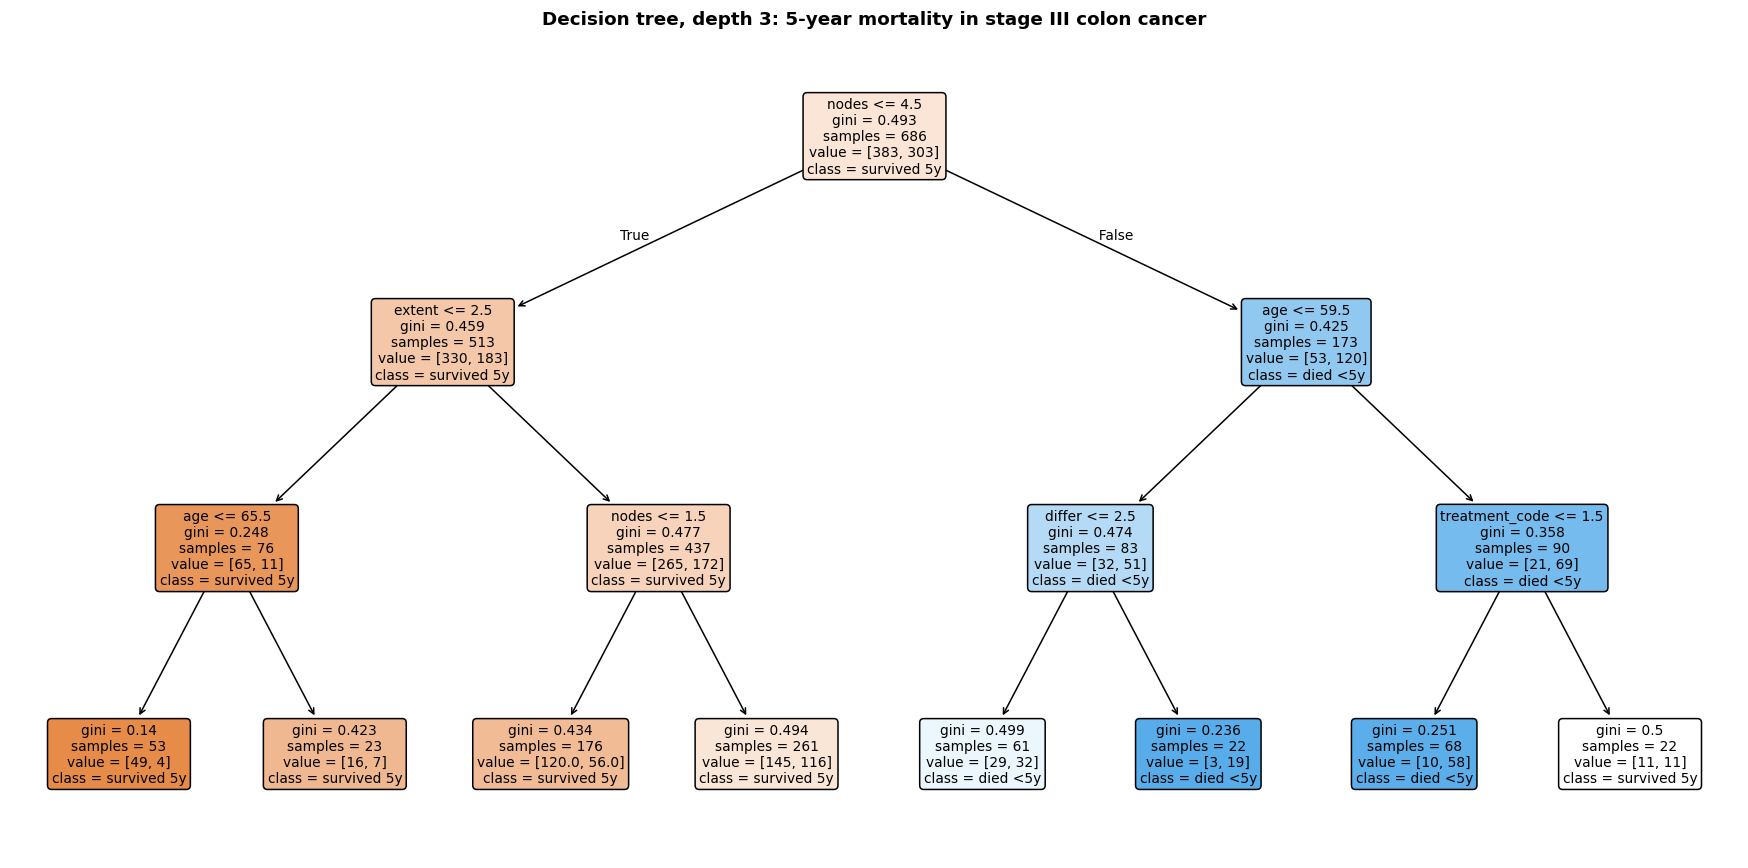

|--- nodes <= 4.50
|   |--- extent <= 2.50
|   |   |--- age <= 65.50
|   |   |   |--- weights: [49.00, 4.00] class: 0
|   |   |--- age >  65.50
|   |   |   |--- weights: [16.00, 7.00] class: 0
|   |--- extent >  2.50
|   |   |--- nodes <= 1.50
|   |   |   |--- weights: [120.00, 56.00] class: 0
|   |   |--- nodes >  1.50
|   |   |   |--- weights: [145.00, 116.00] class: 0
|--- nodes >  4.50
|   |--- age <= 59.50
|   |   |--- differ <= 2.50
|   |   |   |--- weights: [29.00, 32.00] class: 1
|   |   |--- differ >  2.50
|   |   |   |--- weights: [3.00, 19.00] class: 1
|   |--- age >  59.50
|   |   |--- treatment_code <= 1.50
|   |   |   |--- weights: [10.00, 58.00] class: 1
|   |   |--- treatment_code >  1.50
|   |   |   |--- weights: [11.00, 11.00] class: 0



In [8]:
depth_three_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=RANDOM_SEED)
depth_three_tree.fit(training_features, training_labels)

figure, axis = plt.subplots(figsize=(16, 8))
plot_tree(
    depth_three_tree,
    feature_names=tree_feature_names,
    class_names=["survived 5y", "died <5y"],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=9,
    ax=axis,
)
axis.set_title("Decision tree, depth 3: 5-year mortality in stage III colon cancer")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "tree_depth3.png"), bbox_inches="tight")
plt.show()

print(export_text(depth_three_tree, feature_names=tree_feature_names, show_weights=True))

In [9]:
# Observed mortality per terminal node, training vs test
training_leaf_ids = depth_three_tree.apply(training_features)
test_leaf_ids = depth_three_tree.apply(test_features)

leaf_summary = (
    pd.DataFrame({"leaf": training_leaf_ids, "died": training_labels.values})
    .groupby("leaf")["died"].agg(training_n="size", training_mortality="mean")
)
test_leaf_summary = (
    pd.DataFrame({"leaf": test_leaf_ids, "died": test_labels.values})
    .groupby("leaf")["died"].agg(test_n="size", test_mortality="mean")
)
leaf_summary = leaf_summary.join(test_leaf_summary).sort_values("training_mortality")
leaf_summary[["training_mortality", "test_mortality"]] = leaf_summary[["training_mortality", "test_mortality"]].round(3)
leaf_summary

,training_n,training_mortality,test_n,test_mortality
leaf,,,,
3,53,0.075,16,0.125
4,23,0.304,11,0.364
6,176,0.318,51,0.314
7,261,0.444,95,0.432
14,22,0.500,9,0.556
10,61,0.525,21,0.714
13,68,0.853,21,0.667
11,22,0.864,5,0.800


The depth-3 tree stratifies the cohort into eight terminal nodes spanning under 10% to over 80% five-year mortality. Training and test mortality agree closely in the large nodes and diverge in the nodes holding roughly 20 patients, which is the expected behavior of an unpruned tree at this sample size.

One branch is clinically notable. Among patients with more than 4 positive nodes aged 60 or older, the tree splits on treatment: 85% five-year mortality without 5-FU versus 50% with Lev+5FU. This is a treatment-by-risk interaction the tree identified without specification; a Cox model would require an explicit interaction term. The leaf holds 22 patients and the finding should be treated as hypothesis-generating.

### 6.3 Depth selection

Training AUC and 5-fold cross-validated AUC as a function of maximum depth.

In [10]:
candidate_depths = list(range(1, 16))
training_auc_by_depth = []
cross_validated_auc_by_depth = []

for depth in candidate_depths:
    tree_at_this_depth = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_SEED)
    tree_at_this_depth.fit(training_features, training_labels)
    training_probabilities = tree_at_this_depth.predict_proba(training_features)[:, 1]
    training_auc_by_depth.append(roc_auc_score(training_labels, training_probabilities))

    fold_aucs = cross_val_score(tree_at_this_depth, training_features, training_labels, cv=five_fold_cv, scoring="roc_auc")
    cross_validated_auc_by_depth.append(fold_aucs.mean())

depth_curve = pd.DataFrame({
    "max_depth": candidate_depths,
    "training_auc": np.round(training_auc_by_depth, 3),
    "cross_validated_auc": np.round(cross_validated_auc_by_depth, 3),
})
best_depth = int(depth_curve.loc[depth_curve["cross_validated_auc"].idxmax(), "max_depth"])
print(f"Selected depth (max cross-validated AUC): {best_depth}")
depth_curve.T

Selected depth (max cross-validated AUC): 3


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
max_depth,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000,13.000,14.000,15.000
training_auc,0.629,0.669,0.699,0.739,0.779,0.815,0.846,0.881,0.911,0.937,0.961,0.973,0.985,0.992,0.997
cross_validated_auc,0.620,0.636,0.643,0.629,0.623,0.619,0.602,0.602,0.613,0.584,0.584,0.570,0.577,0.577,0.581


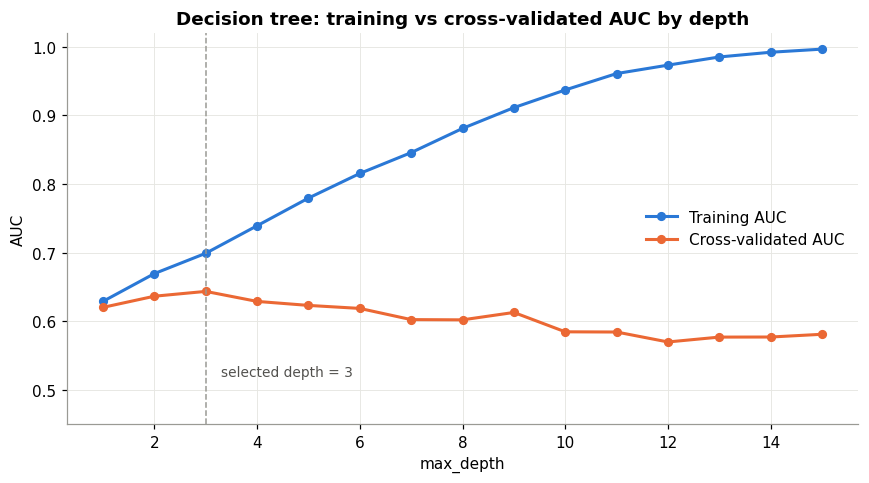

In [11]:
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(candidate_depths, training_auc_by_depth, color=COLOR_BLUE, linewidth=2, marker="o", markersize=5, label="Training AUC")
axis.plot(candidate_depths, cross_validated_auc_by_depth, color=COLOR_ORANGE, linewidth=2, marker="o", markersize=5, label="Cross-validated AUC")
axis.axvline(best_depth, color=COLOR_GRAY, linestyle="--", linewidth=1)
axis.annotate(f"selected depth = {best_depth}", xy=(best_depth, 0.5), xytext=(best_depth + 0.3, 0.52), color="#52514e", fontsize=9)
axis.set_xlabel("max_depth")
axis.set_ylabel("AUC")
axis.set_ylim(0.45, 1.02)
axis.set_title("Decision tree: training vs cross-validated AUC by depth")
axis.legend(loc="center right")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "tree_depth_curve.png"), bbox_inches="tight")
plt.show()

Cross-validated AUC peaks at depth 3 (0.643) and declines steadily beyond it while training AUC approaches 1.0. Depth 3 is carried forward as the single-tree model.

---
## 7. Random forest

500 trees, bootstrap-sampled, with `sqrt(p)` features considered per split and a minimum leaf size of 5. The out-of-bag estimate uses, for each patient, only the trees whose bootstrap sample excluded that patient.

In [12]:
random_forest = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    max_features="sqrt",
    oob_score=True,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
random_forest.fit(training_features, training_labels)

forest_cv_aucs = cross_val_score(random_forest, training_features, training_labels, cv=five_fold_cv, scoring="roc_auc")
print(f"Random forest out-of-bag accuracy: {random_forest.oob_score_:.3f}")
print(f"Random forest cross-validated AUC: {forest_cv_aucs.mean():.3f} (+/- {forest_cv_aucs.std():.3f})")
print(f"Single tree (depth {best_depth}) cross-validated AUC: {max(cross_validated_auc_by_depth):.3f}")

Random forest out-of-bag accuracy: 0.669
Random forest cross-validated AUC: 0.703 (+/- 0.038)
Single tree (depth 3) cross-validated AUC: 0.643


Averaging 500 trees raises cross-validated AUC from 0.643 (single tree) to 0.703.

---
## 8. Gradient boosting

### 8.1 Learning rate and number of rounds

Gradient boosting adds shallow trees sequentially, each fit to the gradient of the loss with respect to the current ensemble, scaled by a learning rate. The number of rounds is the primary regularization parameter and trades off against the learning rate. Cross-validated log loss is traced per round for three learning rates using `staged_predict_proba`, with depth-2 trees, 80% row subsampling, and a minimum leaf size of 10. Each curve is the mean over the 5 validation folds.

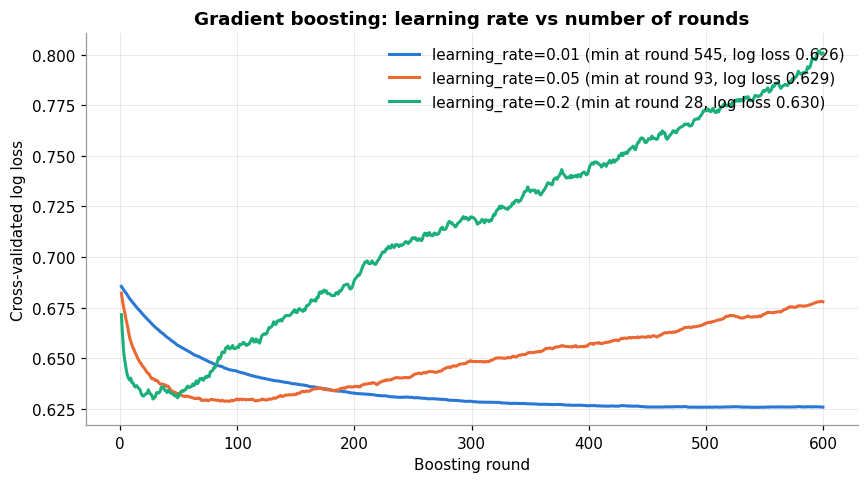

In [13]:
learning_rates_to_compare = [0.01, 0.05, 0.2]
colors_for_learning_rates = [COLOR_BLUE, COLOR_ORANGE, COLOR_AQUA]
MAX_ROUNDS = 600

figure, axis = plt.subplots(figsize=(8, 4.5))

cross_validated_log_loss_curves = {}
for learning_rate, color in zip(learning_rates_to_compare, colors_for_learning_rates):
    per_fold_curves = []
    for fit_index, validation_index in five_fold_cv.split(training_features, training_labels):
        boosted_model = GradientBoostingClassifier(
            n_estimators=MAX_ROUNDS, learning_rate=learning_rate, max_depth=2,
            subsample=0.8, min_samples_leaf=10, random_state=RANDOM_SEED,
        )
        boosted_model.fit(training_features.iloc[fit_index], training_labels.iloc[fit_index])
        validation_log_loss_per_round = [
            log_loss(training_labels.iloc[validation_index], staged_probabilities[:, 1])
            for staged_probabilities in boosted_model.staged_predict_proba(training_features.iloc[validation_index])
        ]
        per_fold_curves.append(validation_log_loss_per_round)
    mean_curve = np.mean(per_fold_curves, axis=0)
    cross_validated_log_loss_curves[learning_rate] = mean_curve
    best_round = int(np.argmin(mean_curve)) + 1
    axis.plot(np.arange(1, MAX_ROUNDS + 1), mean_curve, color=color, linewidth=2,
              label=f"learning_rate={learning_rate} (min at round {best_round}, log loss {mean_curve.min():.3f})")

axis.set_xlabel("Boosting round")
axis.set_ylabel("Cross-validated log loss")
axis.set_title("Gradient boosting: learning rate vs number of rounds")
axis.legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "boosting_learning_rate_curves.png"), bbox_inches="tight")
plt.show()

At a learning rate of 0.2 the validation loss reaches its minimum within about 30 rounds and then rises steeply. At 0.05 the minimum is near round 90 with a slow upward drift afterwards. At 0.01 the minimum is beyond round 500 and is the lowest of the three by a few thousandths. The learning rate primarily determines where the minimum occurs; the attainable minimum is nearly the same provided the number of rounds is chosen at it.

### 8.2 Grid search

Depth, learning rate, number of rounds, and row subsampling are tuned jointly by 5-fold cross-validated AUC (54 configurations).

In [14]:
boosting_parameter_grid = {
    "max_depth": [1, 2, 3],
    "learning_rate": [0.02, 0.05, 0.1],
    "n_estimators": [100, 200, 400],
    "subsample": [0.7, 1.0],
}

boosting_grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(min_samples_leaf=10, random_state=RANDOM_SEED),
    param_grid=boosting_parameter_grid,
    cv=five_fold_cv,
    scoring="roc_auc",
    n_jobs=-1,
    return_train_score=True,
)
boosting_grid_search.fit(training_features, training_labels)

tuned_gradient_boosting = boosting_grid_search.best_estimator_
print("Selected parameters:", boosting_grid_search.best_params_)
print(f"Cross-validated AUC: {boosting_grid_search.best_score_:.3f}")

grid_results = pd.DataFrame(boosting_grid_search.cv_results_)
grid_results = grid_results[["param_max_depth", "param_learning_rate", "param_n_estimators", "param_subsample", "mean_train_score", "mean_test_score", "std_test_score"]]
grid_results.columns = ["max_depth", "learning_rate", "n_estimators", "subsample", "train_auc", "cv_auc", "cv_auc_std"]
grid_results.sort_values("cv_auc", ascending=False).head(8).round(3)

Selected parameters: {'learning_rate': 0.02, 'max_depth': 1, 'n_estimators': 400, 'subsample': 0.7}
Cross-validated AUC: 0.700


,max_depth,learning_rate,n_estimators,subsample,train_auc,cv_auc,cv_auc_std
4,1,0.02,400,0.7,0.751,0.700,0.032
8,2,0.02,200,0.7,0.784,0.700,0.035
10,2,0.02,400,0.7,0.807,0.700,0.026
36,1,0.10,100,0.7,0.754,0.700,0.033
14,3,0.02,200,0.7,0.829,0.698,0.034
20,1,0.05,200,0.7,0.755,0.697,0.031
38,1,0.10,200,0.7,0.766,0.697,0.026
12,3,0.02,100,0.7,0.802,0.697,0.034


The top configurations are separated by a few thousandths of AUC, an order of magnitude below the fold-to-fold standard deviation; the response surface is flat near its optimum. Two features of the table matter for interpretation:

- The selected configuration uses `max_depth=1`. A sum of depth-1 trees is additive in the features with no interaction terms, so the tuned model has the same additive structure as Cox but with unconstrained per-feature response shapes.
- The gap between training and cross-validated AUC widens with depth at equal cross-validated performance (0.75 at depth 1 versus 0.83 at depth 3), consistent with deeper trees fitting training noise that does not generalize.

### 8.3 XGBoost with early stopping

The same model family in XGBoost, with L2 leaf regularization, column subsampling, and early stopping on a 20% validation slice carved from the training set. The test set is not used for stopping.

Best iteration: 243
Validation log loss at best iteration: 0.5725


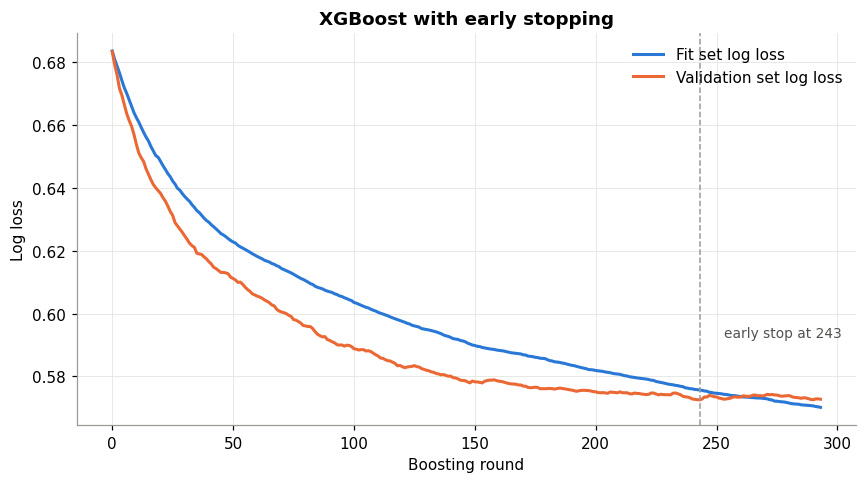

In [15]:
fit_features, early_stop_features, fit_labels, early_stop_labels = train_test_split(
    training_features, training_labels, test_size=0.2, stratify=training_labels, random_state=RANDOM_SEED
)

xgboost_model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=2,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    eval_metric="logloss",
    early_stopping_rounds=50,
    random_state=RANDOM_SEED,
)
xgboost_model.fit(
    fit_features, fit_labels,
    eval_set=[(fit_features, fit_labels), (early_stop_features, early_stop_labels)],
    verbose=False,
)

print(f"Best iteration: {xgboost_model.best_iteration}")
print(f"Validation log loss at best iteration: {xgboost_model.best_score:.4f}")

xgboost_history = xgboost_model.evals_result()
fit_curve = xgboost_history["validation_0"]["logloss"]
early_stop_curve = xgboost_history["validation_1"]["logloss"]

figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(fit_curve, color=COLOR_BLUE, linewidth=2, label="Fit set log loss")
axis.plot(early_stop_curve, color=COLOR_ORANGE, linewidth=2, label="Validation set log loss")
axis.axvline(xgboost_model.best_iteration, color=COLOR_GRAY, linestyle="--", linewidth=1)
axis.annotate(f"early stop at {xgboost_model.best_iteration}", xy=(xgboost_model.best_iteration, min(early_stop_curve)),
              xytext=(xgboost_model.best_iteration + 10, min(early_stop_curve) + 0.02), color="#52514e", fontsize=9)
axis.set_xlabel("Boosting round")
axis.set_ylabel("Log loss")
axis.set_title("XGBoost with early stopping")
axis.legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "xgboost_early_stopping.png"), bbox_inches="tight")
plt.show()

---
## 9. Cox proportional hazards reference model

Fit on the training patients using full time-to-event data (including the early-censored patients the classifiers exclude), with a small L2 penalty for numerical stability. Predicted 5-year mortality for each test patient is `1 - S(5)` from the fitted survival function.

---
## 10. Test-set evaluation

Metrics on the held-out 229 patients: AUC with a 1000-resample bootstrap 95% interval, log loss, and Brier score.

In [16]:
cox_feature_names = [
    "age", "sex", "nodes", "differ", "extent", "obstruct", "perfor", "adhere", "surg",
    "treatment_lev", "treatment_lev_5fu", "nodes_was_missing",
]
cox_training_table = training_patients[cox_feature_names + ["time_to_death_years", "died"]]

cox_model = CoxPHFitter(penalizer=0.01)
cox_model.fit(cox_training_table, duration_col="time_to_death_years", event_col="died")

cox_survival_at_5_years = cox_model.predict_survival_function(test_patients[cox_feature_names], times=[LANDMARK_YEARS])
cox_test_probabilities = 1 - cox_survival_at_5_years.iloc[0].values

best_single_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=10, random_state=RANDOM_SEED)
best_single_tree.fit(training_features, training_labels)

test_probabilities_by_model = {
    "Cox PH": cox_test_probabilities,
    f"Decision tree (depth {best_depth})": best_single_tree.predict_proba(test_features)[:, 1],
    "Random forest": random_forest.predict_proba(test_features)[:, 1],
    "Gradient boosting (tuned)": tuned_gradient_boosting.predict_proba(test_features)[:, 1],
    "XGBoost (early stopped)": xgboost_model.predict_proba(test_features)[:, 1],
}

def bootstrap_auc_interval(true_labels, predicted_probabilities, number_of_resamples=1000):
    rng = np.random.default_rng(RANDOM_SEED)
    true_labels = np.asarray(true_labels)
    resampled_aucs = []
    for _ in range(number_of_resamples):
        resample_index = rng.integers(0, len(true_labels), len(true_labels))
        if len(np.unique(true_labels[resample_index])) < 2:
            continue
        resampled_aucs.append(roc_auc_score(true_labels[resample_index], predicted_probabilities[resample_index]))
    return np.percentile(resampled_aucs, [2.5, 97.5])

comparison_rows = []
for model_name, probabilities in test_probabilities_by_model.items():
    auc_low, auc_high = bootstrap_auc_interval(test_labels, probabilities)
    comparison_rows.append({
        "model": model_name,
        "test_auc": roc_auc_score(test_labels, probabilities),
        "auc_95ci": f"{auc_low:.3f} to {auc_high:.3f}",
        "test_log_loss": log_loss(test_labels, np.clip(probabilities, 1e-6, 1 - 1e-6)),
        "test_brier": brier_score_loss(test_labels, probabilities),
    })
model_comparison = pd.DataFrame(comparison_rows).set_index("model").round(3)
model_comparison

,test_auc,auc_95ci,test_log_loss,test_brier
model,,,,
Cox PH,0.652,0.584 to 0.722,0.650,0.228
Decision tree (depth 3),0.637,0.578 to 0.696,0.671,0.236
Random forest,0.688,0.621 to 0.753,0.621,0.218
Gradient boosting (tuned),0.693,0.628 to 0.757,0.630,0.220
XGBoost (early stopped),0.681,0.619 to 0.746,0.628,0.221


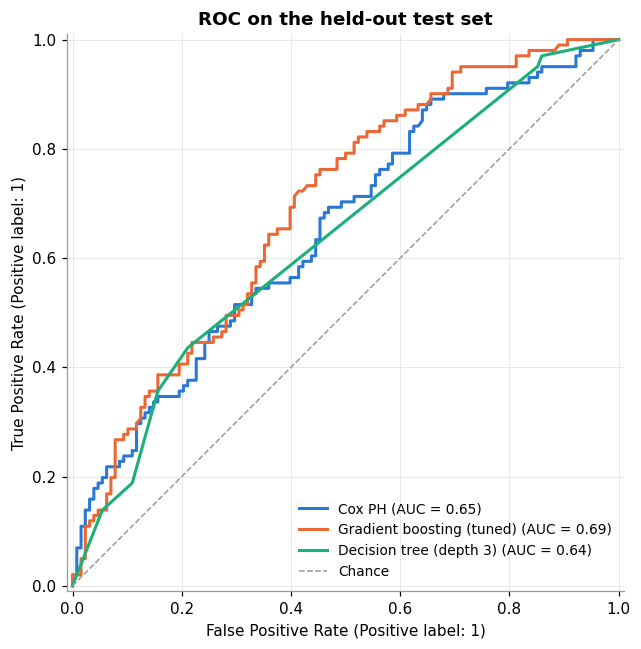

In [17]:
figure, axis = plt.subplots(figsize=(6, 6))
for model_name, color in [("Cox PH", COLOR_BLUE), ("Gradient boosting (tuned)", COLOR_ORANGE), (f"Decision tree (depth {best_depth})", COLOR_AQUA)]:
    RocCurveDisplay.from_predictions(
        test_labels, test_probabilities_by_model[model_name], name=model_name, ax=axis, plot_chance_level=False,
        curve_kwargs={"color": color, "linewidth": 2},
    )
axis.plot([0, 1], [0, 1], color=COLOR_GRAY, linestyle="--", linewidth=1, label="Chance")
axis.set_title("ROC on the held-out test set")
axis.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "roc_test_set.png"), bbox_inches="tight")
plt.show()

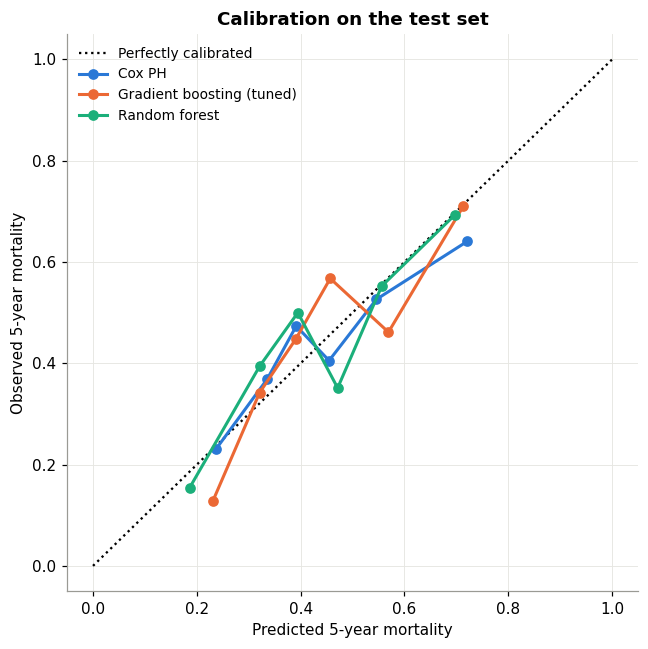

In [18]:
figure, axis = plt.subplots(figsize=(6, 6))
for model_name, color in [("Cox PH", COLOR_BLUE), ("Gradient boosting (tuned)", COLOR_ORANGE), ("Random forest", COLOR_AQUA)]:
    CalibrationDisplay.from_predictions(
        test_labels, test_probabilities_by_model[model_name], n_bins=6, strategy="quantile",
        name=model_name, color=color, linewidth=2, marker="o", markersize=6, ax=axis,
    )
axis.set_title("Calibration on the test set")
axis.set_xlabel("Predicted 5-year mortality")
axis.set_ylabel("Observed 5-year mortality")
axis.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "calibration_test_set.png"), bbox_inches="tight")
plt.show()

### Results

The three ensemble models (random forest, tuned gradient boosting, XGBoost) achieve test AUCs of 0.68 to 0.69 against 0.65 for Cox, with correspondingly lower log loss and Brier scores. The single depth-3 tree is the weakest model at 0.64. All five bootstrap intervals overlap, so the ensemble advantage of 0.03 to 0.04 AUC is consistent across three methods but not statistically established at this test-set size. Calibration is acceptable for all three models shown; deviations from the diagonal are within the sampling noise of 38-patient bins, with no systematic over- or under-confidence.

Three properties of the data limit the achievable gain over Cox: the training set is small (686 patients), the covariate set is small (13 features), and the grid search selected an additive model, indicating that interactions contribute little. The improvement that does appear is attributable to non-linear per-feature response, examined next.

---
## 11. Model interpretation

### 11.1 Permutation importance

Mean decrease in test AUC over 50 random permutations of each feature, for the tuned gradient boosting model. Impurity-based importance from the same model is shown alongside for contrast; it is computed on training data and favors continuous features with many candidate split points.

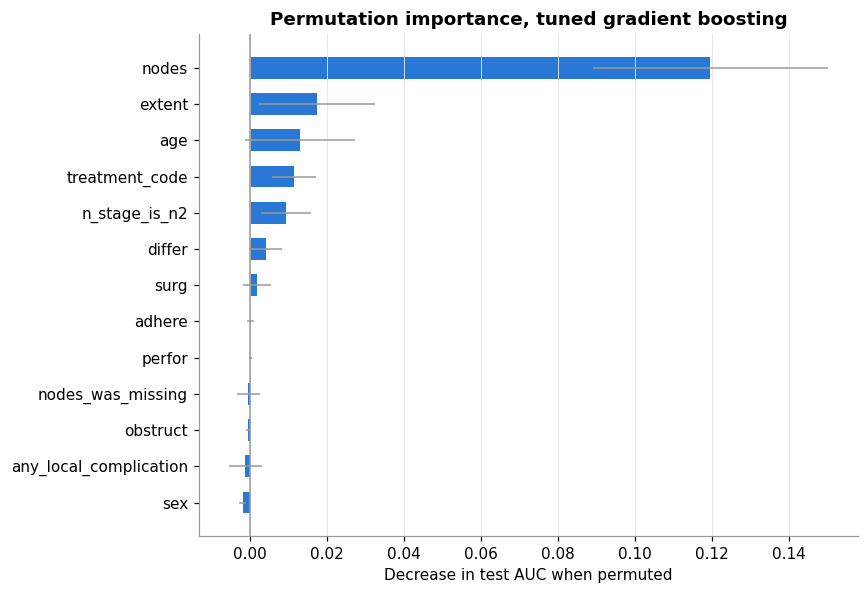

,feature,auc_drop_when_shuffled,std,impurity_importance
2,nodes,0.1197,0.0305,0.4121
4,extent,0.0174,0.0151,0.1396
0,age,0.0130,0.0143,0.1725
9,treatment_code,0.0114,0.0056,0.0359
11,n_stage_is_n2,0.0094,0.0066,0.0911
3,differ,0.0041,0.0042,0.0452
8,surg,0.0019,0.0037,0.0225
7,adhere,0.0001,0.0010,0.0072
6,perfor,0.0001,0.0004,0.0015
10,nodes_was_missing,-0.0004,0.0029,0.0203


In [19]:
permutation_result = permutation_importance(
    tuned_gradient_boosting, test_features, test_labels,
    scoring="roc_auc", n_repeats=50, random_state=RANDOM_SEED, n_jobs=-1,
)
permutation_table = pd.DataFrame({
    "feature": tree_feature_names,
    "auc_drop_when_shuffled": permutation_result.importances_mean,
    "std": permutation_result.importances_std,
    "impurity_importance": tuned_gradient_boosting.feature_importances_,
}).sort_values("auc_drop_when_shuffled", ascending=True)

figure, axis = plt.subplots(figsize=(8, 5.5))
axis.barh(permutation_table["feature"], permutation_table["auc_drop_when_shuffled"],
          xerr=permutation_table["std"], color=COLOR_BLUE, height=0.6, error_kw={"ecolor": COLOR_GRAY, "elinewidth": 1})
axis.axvline(0, color=COLOR_GRAY, linewidth=1)
axis.set_xlabel("Decrease in test AUC when permuted")
axis.set_title("Permutation importance, tuned gradient boosting")
axis.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "permutation_importance.png"), bbox_inches="tight")
plt.show()

permutation_table.sort_values("auc_drop_when_shuffled", ascending=False).round(4)

Nodal burden dominates: permuting `nodes` reduces test AUC by about 0.12. Local extent, age, and treatment arm form a second tier at 0.01 to 0.02 each, followed by differentiation. Sex, obstruction, perforation, adherence, and the missingness indicator contribute nothing measurable.

Of the two derived features, the N2 indicator carries a small importance that is redundant with `nodes`, since the model can locate the same threshold directly. The local-complication composite has an impurity importance of 0.045, comparable to differentiation, but a permutation importance at zero: the model used it in training splits and those splits did not improve prediction on held-out patients. The composite is not supported and would be dropped in a refit.

### 11.2 Partial dependence

Partial dependence on `nodes` and `age` for the tuned gradient boosting model and the Cox model, computed by the same procedure: each feature is set to a fixed value for every training patient with all other covariates unchanged, and the predicted 5-year mortality is averaged. The node grid is capped at the 98th percentile.

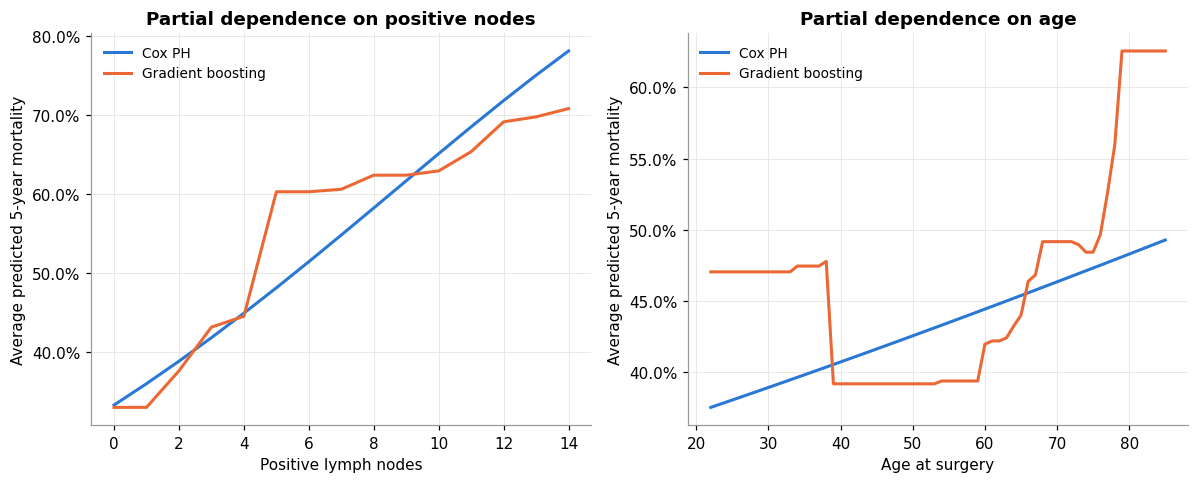

nodes,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
cox,0.333,0.36,0.388,0.418,0.449,0.481,0.514,0.548,0.582,0.617,0.651,0.685,0.718,0.750,0.781
boosting,0.330,0.33,0.376,0.431,0.445,0.603,0.603,0.606,0.624,0.624,0.629,0.653,0.691,0.697,0.708


In [20]:
def partial_dependence(predict_risk, feature_table, feature_name, grid_values):
    average_risk_at_each_value = []
    for value in grid_values:
        counterfactual_table = feature_table.copy()
        counterfactual_table[feature_name] = value
        average_risk_at_each_value.append(predict_risk(counterfactual_table).mean())
    return np.array(average_risk_at_each_value)

def boosting_predict_risk(feature_table):
    return tuned_gradient_boosting.predict_proba(feature_table[tree_feature_names])[:, 1]

def cox_predict_risk(feature_table):
    survival_at_5 = cox_model.predict_survival_function(feature_table[cox_feature_names], times=[LANDMARK_YEARS])
    return 1 - survival_at_5.iloc[0].values

node_grid = np.arange(0, int(training_features["nodes"].quantile(0.98)) + 1)
age_grid = np.arange(int(training_features["age"].min()), int(training_features["age"].max()) + 1)
training_table_for_pdp = training_patients.copy()

boosting_pd_nodes = partial_dependence(boosting_predict_risk, training_table_for_pdp, "nodes", node_grid)
cox_pd_nodes = partial_dependence(cox_predict_risk, training_table_for_pdp, "nodes", node_grid)
boosting_pd_age = partial_dependence(boosting_predict_risk, training_table_for_pdp, "age", age_grid)
cox_pd_age = partial_dependence(cox_predict_risk, training_table_for_pdp, "age", age_grid)

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(node_grid, cox_pd_nodes, color=COLOR_BLUE, linewidth=2, label="Cox PH")
axes[0].plot(node_grid, boosting_pd_nodes, color=COLOR_ORANGE, linewidth=2, label="Gradient boosting")
axes[1].plot(age_grid, cox_pd_age, color=COLOR_BLUE, linewidth=2, label="Cox PH")
axes[1].plot(age_grid, boosting_pd_age, color=COLOR_ORANGE, linewidth=2, label="Gradient boosting")

for axis, feature_label in zip(axes, ["Positive lymph nodes", "Age at surgery"]):
    axis.set_xlabel(feature_label)
    axis.set_ylabel("Average predicted 5-year mortality")
    axis.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    axis.legend(loc="upper left", fontsize=9)
axes[0].set_title("Partial dependence on positive nodes")
axes[1].set_title("Partial dependence on age")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "partial_dependence_nodes_age.png"), bbox_inches="tight")
plt.show()

pd.DataFrame({"nodes": node_grid, "cox": np.round(cox_pd_nodes, 3), "boosting": np.round(boosting_pd_nodes, 3)}).set_index("nodes").T

**Nodes.** The Cox curve rises smoothly across the full range, as the proportional hazards form requires; predicted mortality at 10 nodes exceeds that at 5 nodes by 17 points. The boosted model is piecewise constant (a sum of depth-1 trees) and shows a different shape: a rise from 2 to 4 nodes, a sharp step at 5 nodes coinciding with the root split in Section 6.1, a plateau from 5 to 10 nodes with only about 3 points of separation, and a further rise beyond 10. The two models agree at the extremes and disagree in the middle of the range, where most of the N2 patients sit. This plateau is the principal structural difference between the models and the most plausible source of the ensembles' test-set advantage.

**Age.** Both models are flat through middle age and rise after 60. The boosted model additionally shows a raised shelf below 40 and a step at 78. Fewer than a quarter of patients are under 53 and very few are under 40 or over 78, so these features rest on a handful of patients each and should not be interpreted. The Cox line is the more defensible summary in the sparse tails.

---
## 12. Conclusions and limitations

**Findings**

- The first data-driven split on this cohort is nodal burden at more than 4 positive nodes, matching the trial's own `node4` covariate and the AJCC N1/N2 boundary within one node.
- Tuned gradient boosting selected an additive (depth-1) structure. On this cohort, flexible per-feature response improves prediction; interactions do not contribute measurably.
- Random forest, gradient boosting, and XGBoost each exceed Cox by 0.03 to 0.04 test AUC with better log loss and Brier score. The bootstrap intervals overlap, so the advantage is consistent but not statistically established on 229 test patients.
- Partial dependence identifies a plateau in 5-year mortality between 5 and 10 positive nodes that the proportional hazards form cannot represent.
- Permutation importance on the test set rejects the local-complication composite feature despite its non-trivial impurity importance.

**Limitations**

- Sample size. 686 training and 229 test patients limit both the complexity the ensembles can exploit and the precision of the comparison.
- The landmark outcome discards 14 early-censored patients and compresses time-to-event into a binary. A survival-aware boosting model (for example `scikit-survival`'s `GradientBoostingSurvivalAnalysis`) would use the censored information directly.
- Trial population. Patients are from academic centers in 1984 to 1987 with stage III disease only; generalization to community practice or to other stages is not supported by this analysis.
- A single random split. Repeated splits or nested cross-validation would tighten the comparison at the cost of compute.

**Extensions**

1. Disease-free survival as a second endpoint; the recurrence columns are already in the patient table.
2. Survival-aware gradient boosting on the full censored data.
3. The same pipeline on SEER registry data, where sample size, subsite, MSI status, and demographic covariates would allow the interaction capacity of deeper trees to be tested.

---
## Appendix A. Minimal gradient boosting implementation

The library models above are compared against a minimal L2 gradient boosting loop built from scikit-learn regression trees, as a check that the observed training-versus-test behavior is a property of the algorithm rather than of a library default. Each round fits a depth-2 regression tree to the current residuals and adds its predictions scaled by a learning rate of 0.1. Squared error is used for transparency; the library classifiers optimize log loss on the logit scale.

Test MSE minimum at round 24; test AUC there 0.690


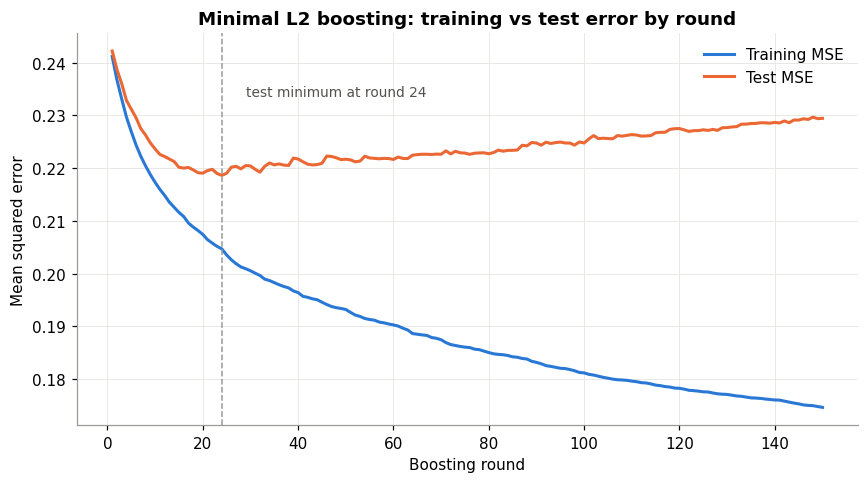

In [21]:
LEARNING_RATE_BY_HAND = 0.1
NUMBER_OF_ROUNDS_BY_HAND = 150
SMALL_TREE_DEPTH = 2

running_training_prediction = np.full(len(training_labels), training_labels.mean())
running_test_prediction = np.full(len(test_labels), training_labels.mean())

training_error_by_round = []
test_error_by_round = []
test_auc_by_round = []

for round_number in range(NUMBER_OF_ROUNDS_BY_HAND):
    residuals = training_labels.values - running_training_prediction
    correction_tree = DecisionTreeRegressor(max_depth=SMALL_TREE_DEPTH, random_state=RANDOM_SEED)
    correction_tree.fit(training_features, residuals)
    running_training_prediction += LEARNING_RATE_BY_HAND * correction_tree.predict(training_features)
    running_test_prediction += LEARNING_RATE_BY_HAND * correction_tree.predict(test_features)

    training_error_by_round.append(np.mean((training_labels.values - running_training_prediction) ** 2))
    test_error_by_round.append(np.mean((test_labels.values - running_test_prediction) ** 2))
    test_auc_by_round.append(roc_auc_score(test_labels, running_test_prediction))

rounds = np.arange(1, NUMBER_OF_ROUNDS_BY_HAND + 1)
best_round_by_hand = int(rounds[np.argmin(test_error_by_round)])
print(f"Test MSE minimum at round {best_round_by_hand}; test AUC there {test_auc_by_round[best_round_by_hand - 1]:.3f}")

figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(rounds, training_error_by_round, color=COLOR_BLUE, linewidth=2, label="Training MSE")
axis.plot(rounds, test_error_by_round, color=COLOR_ORANGE, linewidth=2, label="Test MSE")
axis.axvline(best_round_by_hand, color=COLOR_GRAY, linestyle="--", linewidth=1)
axis.annotate(f"test minimum at round {best_round_by_hand}", xy=(best_round_by_hand, min(test_error_by_round)),
              xytext=(best_round_by_hand + 5, min(test_error_by_round) + 0.015), color="#52514e", fontsize=9)
axis.set_xlabel("Boosting round")
axis.set_ylabel("Mean squared error")
axis.set_title("Minimal L2 boosting: training vs test error by round")
axis.legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "boosting_by_hand.png"), bbox_inches="tight")
plt.show()

The minimal implementation reproduces the pattern seen in Section 8: monotone decrease in training error and a test-error minimum within the first few dozen rounds followed by slow degradation.

---
## Appendix B. Invariance of tree splits to monotone transforms

Supporting the decision in Section 4 not to transform numeric features. The same depth-3 tree is fit on `nodes`, on `log(1 + nodes)`, and on the binned N2 indicator.

In [22]:
labels_all = classification_cohort[target_name]

tree_on_raw_nodes = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_SEED)
tree_on_raw_nodes.fit(classification_cohort[["nodes"]], labels_all)

tree_on_log_nodes = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_SEED)
tree_on_log_nodes.fit(np.log1p(classification_cohort[["nodes"]]), labels_all)

tree_on_binned_nodes = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_SEED)
tree_on_binned_nodes.fit(classification_cohort[["n_stage_is_n2"]], labels_all)

predictions_raw = tree_on_raw_nodes.predict_proba(classification_cohort[["nodes"]])[:, 1]
predictions_log = tree_on_log_nodes.predict_proba(np.log1p(classification_cohort[["nodes"]]))[:, 1]
predictions_binned = tree_on_binned_nodes.predict_proba(classification_cohort[["n_stage_is_n2"]])[:, 1]

print("raw nodes vs log(nodes): predictions identical?", np.allclose(predictions_raw, predictions_log))
print("raw nodes vs binned:     predictions identical?", np.allclose(predictions_raw, predictions_binned))

raw_thresholds = tree_on_raw_nodes.tree_.threshold[tree_on_raw_nodes.tree_.threshold > 0]
log_thresholds = tree_on_log_nodes.tree_.threshold[tree_on_log_nodes.tree_.threshold > 0]
print("Thresholds, raw-nodes tree:         ", sorted({round(float(t), 2) for t in raw_thresholds}))
print("Thresholds, log-nodes tree (expm1): ", sorted({round(float(np.expm1(t)), 2) for t in log_thresholds}))

raw nodes vs log(nodes): predictions identical? True
raw nodes vs binned:     predictions identical? False
Thresholds, raw-nodes tree:          [0.5, 2.5, 3.5, 4.5, 5.5, 11.5, 19.5]
Thresholds, log-nodes tree (expm1):  [0.41, 2.46, 3.47, 4.48, 5.48, 11.49, 19.49]


The log transform yields an identical tree with identical thresholds expressed on the transformed scale. Binning changes the tree because it discards within-bin ordering.